# Week 8 Take Home

This week has two parts:

| Part | Lessons | Take-home work |
|------|---------|----------------|
| **A. Grouping & Aggregating Data** | `1-Grouping & Aggregating Data/` (notebooks 1–4) | Project 4 below + the notebook task solutions |
| **B. Data Visualization** | `2-Data Visualization (Seaborn & Matplotlib)/` (videos + scripts) | Re-create the plots from the videos using the Part A milk data: a histogram, a KDE plot, a box/violin plot, a regression plot and a heatmap. Add them at the end of this notebook. |

Part A data comes from the cohort database (schema `week09`). See `Data Access (SQL).md`.

---
# Part A: Grouping & Aggregating Data

## Project 4: Exploring the UK's milk imports and exports

A country's economy depends, sometimes heavily, on its exports and imports. The United Nations Comtrade database provides data on global trade. It will be used to analyse the UK's imports and exports of milk and cream in 2015:

- How much does the UK export and import and is the balance positive (more exports than imports)? 
- Which are the main trading partners, i.e. from/to which countries does the UK import/export the most?
- Which are the regular customers, i.e. which countries buy milk from the UK every month?
- Which countries does the UK both import from and export to?

In [1]:
import warnings
warnings.simplefilter('ignore', FutureWarning)

from pandas import *
%matplotlib inline

## Getting and preparing the data

The data is obtained from the [United Nations Comtrade](http://comtrade.un.org/data/) website, by selecting the following configuration:

- Type of Product: goods
- Frequency: monthly 
- Periods: January to May of 2015
- Reporter: United Kingdom
- Partners: all
- Flows: imports and exports
- HS (as reported) commodity codes: 0401 (Milk and cream, neither concentrated nor sweetened) and 0402 (Milk and cream, concentrated or sweetened)

Clicking on 'Preview' results in a message that the data exceeds 500 rows. Data was downloaded using the *Download CSV* button and the download file renamed appropriately.

In [2]:
LOCATION = 'comtrade_milk_uk_jan_jul_15.csv'

The data can also be downloaded directly from Comtrade using the "View API Call" URL, modified in two ways:

- `max=500` is increased to `max=5000` to make sure all data is loaded,
- `&fmt=csv` is added at the end to obtain the data in CSV format.

In [3]:
# LOCATION = 'http://comtrade.un.org/api/get?max=5000&type=C&freq=M&px=HS&ps=201505%2C201504%2C201503%2C201502%2C201501&r=826&p=all&rg=1%2C2&cc=0401%2C0402&fmt=csv'

On reading in the data, the commodity code has to be read as a string, to not lose the leading zero.

In [4]:
# Load Data from cohort database (schema week09). See "Data Access (SQL).md".
import sys, pathlib
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))
from db.dataraflow_db import run_query

milk = run_query("SELECT * FROM week09.comtrade_milk_uk_jan_jul_15")
milk.tail(2)


,Classification,Year,Period,Period Desc.,Aggregate Level,Is Leaf Code,Trade Flow Code,Trade Flow,Reporter Code,Reporter,...,Qty,Alt Qty Unit Code,Alt Qty Unit,Alt Qty,Netweight (kg),Gross weight (kg),Trade Value (US$),CIF Trade Value (US$),FOB Trade Value (US$),Flag
635,HS,2015,201505,May 2015,4,0,2,Exports,826,United Kingdom,...,None,None,None,None,2213,None,37883,None,None,0
636,HS,2015,201505,May 2015,4,0,2,Exports,826,United Kingdom,...,None,None,None,None,1588,None,5676,None,None,0


The data only covers the first five months of 2015. Most columns are irrelevant for this analysis, or contain always the same value, like the year and reporter columns. The commodity code is transformed into a short but descriptive text and only the relevant columns are selected.

In [5]:
def milkType(code):
    if code == '0401': # neither concentrated nor sweetened
        return 'unprocessed'
    if code == '0402': # concentrated or sweetened
        return 'processed' 
    return 'unknown'

COMMODITY = 'Milk and cream'
milk[COMMODITY] = milk['Commodity Code'].apply(milkType)
MONTH = 'Period'
PARTNER = 'Partner'
FLOW = 'Trade Flow'
VALUE = 'Trade Value (US$)'
headings = [MONTH, PARTNER, FLOW, COMMODITY, VALUE]
milk = milk[headings]
milk.head()

,Period,Partner,Trade Flow,Milk and cream,Trade Value (US$)
0,201501,World,Imports,unprocessed,14104602
1,201501,World,Exports,unprocessed,26259792
2,201501,Australia,Exports,unprocessed,50331
3,201501,Austria,Exports,unprocessed,360
4,201501,Belgium,Imports,unprocessed,1424271


The data contains the total imports and exports per month, under the 'World' partner. Those rows are removed to keep only the per-country data.

In [6]:
milk = milk[milk[PARTNER] != 'World']
milk.head()

,Period,Partner,Trade Flow,Milk and cream,Trade Value (US$)
2,201501,Australia,Exports,unprocessed,50331
3,201501,Austria,Exports,unprocessed,360
4,201501,Belgium,Imports,unprocessed,1424271
5,201501,Belgium,Exports,unprocessed,996031
6,201501,Bulgaria,Exports,unprocessed,191


## Total trade flow

To answer the first question, 'how much does the UK export and import and is the balance positive (more exports than imports)?',
the dataframe is split into two groups: exports from the UK and imports into the UK. The  trade values within each group are summed up to get the total trading.

In [7]:
grouped = milk.groupby([FLOW])
grouped[VALUE].aggregate(sum)

Trade Flow
Exports    265029661
Imports    156483978
Name: Trade Value (US$), dtype: int64

This shows a trade surplus of over 100 million dollars.

## Main trade partners

To address the second question, 'Which are the main trading partners, i.e. from/to which countries does the UK import/export the most?', the dataframe is split by country instead, and then each group aggregated for the total trade value. This is done separately for imports and exports. The result is sorted in descending order so that the main partners are at the top.

In [8]:
imports = milk[milk[FLOW] == 'Imports']
grouped = imports.groupby([PARTNER])
print('The UK imports from', len(grouped), 'countries.')
print('The 5 biggest exporters to the UK are:')
totalImports = grouped[VALUE].aggregate(sum).sort_values(inplace=False,ascending=False)
totalImports.head()

The UK imports from 21 countries.
The 5 biggest exporters to the UK are:


Partner
Ireland        46263897
France         28314091
Germany        21899123
Netherlands    17658912
Belgium        14325697
Name: Trade Value (US$), dtype: int64

The export values can be plotted as a bar chart, making differences between countries easier to see.

<Axes: ylabel='Partner'>

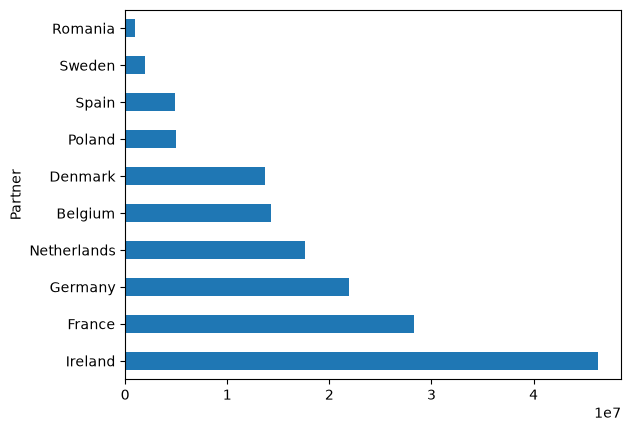

In [9]:
totalImports.head(10).plot(kind='barh')

In [10]:
exports = milk[milk[FLOW] == 'Exports']
grouped = exports.groupby([PARTNER])
print('The UK exports to', len(grouped), 'countries.')
print('The 5 biggest importers from the UK are:')
grouped[VALUE].aggregate(sum).sort_values(ascending=False,inplace=False).head()

The UK exports to 107 countries.
The 5 biggest importers from the UK are:


Partner
Ireland                 128155891
Netherlands              18018603
China                    14111163
Germany                  10828464
China, Hong Kong SAR      9482458
Name: Trade Value (US$), dtype: int64

## Regular importers

Given that there are two commodities, the third question, 'Which are the regular customers, i.e. which countries buy milk from the UK every month?', is meant in the sense that a regular customer imports both commodities every month. This means that if the exports dataframe is grouped by country, each group has exactly ten rows (two commodities bought each of the five months). To see the countries, only the first month of one commodity has to be listed, as by definition it's the same countries every month and for the other commodity.

In [11]:
def buysEveryMonth(group):
    return len(group) == 10

grouped = exports.groupby([PARTNER])
regular = grouped.filter(buysEveryMonth)
regular[(regular[MONTH] == 201501) & (regular[COMMODITY] == 'processed')]

,Period,Partner,Trade Flow,Milk and cream,Trade Value (US$)
268,201501,Belgium,Exports,processed,142610
271,201501,China,Exports,processed,1013141
275,201501,Cyprus,Exports,processed,6625
280,201501,Denmark,Exports,processed,107883
284,201501,France,Exports,processed,178262
287,201501,Germany,Exports,processed,2588380
292,201501,"China, Hong Kong SAR",Exports,processed,1110086
294,201501,Hungary,Exports,processed,2119
298,201501,Ireland,Exports,processed,4020981
300,201501,Italy,Exports,processed,23267


Just over 75% of the total UK exports are due to these regular customers.

In [12]:
regular[VALUE].sum() / exports[VALUE].sum()

np.float64(0.7583526396315317)

## Bi-directional trade

To address the fourth question, 
'Which countries does the UK both import from and export to?', a pivot table is used to list the total export and import value for each country. 

In [13]:
countries = pivot_table(milk, index=[PARTNER], columns=[FLOW], 
                        values=VALUE, aggfunc=sum)
countries.head()

Trade Flow,Exports,Imports
Partner,,
Algeria,8087885.0,NaN
Angola,2416129.0,NaN
Antigua and Barbuda,22218.0,NaN
"Areas, nes",51205.0,NaN
Australia,81644.0,NaN


Removing the rows with a missing value will result in only those countries with bi-directional trade flow with the UK.

In [14]:
countries.dropna()

Trade Flow,Exports,Imports
Partner,,
Austria,56279.0,780.0
Belgium,7209121.0,14325697.0
Czech Rep.,2590.0,486889.0
Denmark,335068.0,13681759.0
France,9381762.0,28314091.0
Germany,10828464.0,21899123.0
Hungary,71378.0,4762.0
Ireland,128155891.0,46263897.0
Italy,173689.0,321635.0


## Provide `1-Grouping & Aggregating Data/1.ipynb` Tasks Solutions below (Execute them)

In [15]:
import sys
from pathlib import Path
import pandas as pd

# --- STEP 1: DYNAMIC PATH SETUP ---
# Locate the root workspace directory by walking up parent folders
# until we find the 'db/dataraflow_db.py' utility module.
_p = Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))

# Import the database query runner function from course utilities
from db.dataraflow_db import run_query


# --- STEP 2: LOAD DATA FROM COHORT DATABASE ---
# Load the monthly UK Comtrade milk trade data from the week09 schema.
# Commodity/Reporter codes are stored as text to preserve leading zeros.
milk = run_query("SELECT * FROM week09.comtrade_milk_uk_monthly_14")

print("--- Step 2: Raw Data Sample ---")
print(milk.head(3))


# --- STEP 3: LIMIT COLUMNS TO A USABLE SUBSET ---
# Select a subset of relevant columns to make the DataFrame easier to work with
COLUMNS = [
    'Year', 
    'Period', 
    'Trade Flow', 
    'Reporter', 
    'Partner', 
    'Commodity', 
    'Commodity Code', 
    'Trade Value (US$)'
]
milk = milk[COLUMNS]

print("\n--- Step 3: Filtered Columns Sample ---")
print(milk.head(3))


# --- STEP 4: DERIVE SUBSETS FOR WORLD VS. INDIVIDUAL COUNTRIES ---
# Separate out rows where the partner is 'World' versus individual partner countries
milk_world = milk[milk['Partner'] == 'World']
milk_countries = milk[milk['Partner'] != 'World']

print(f"\n--- Step 4: Row Counts ---")
print(f"World Partner Rows: {len(milk_world)}")
print(f"Individual Country Partner Rows: {len(milk_countries)}")


# --- STEP 5: SUBSETTING DATA BY TRADE FLOW (IMPORTS) ---
# Filter specifically for 'Imports' across the dataset and country subsets
milk_imports = milk[milk['Trade Flow'] == 'Imports']
milk_countries_imports = milk_countries[milk_countries['Trade Flow'] == 'Imports']
milk_world_imports = milk_world[milk_world['Trade Flow'] == 'Imports']


# --- STEP 6: SORTING AND ANALYZING TOP IMPORT PARTNERS ---
# Find the most valuable import partners during January 2014 (Period '201401')
# by sorting the data in descending order of Trade Value.
period_to_check = 201401
milk_imports_in_jan = milk_countries_imports[
    milk_countries_imports['Period'] == period_to_check
]

# Sort by Trade Value in descending order and select the top 10 partners
top_import_partners = milk_imports_in_jan.sort_values(
    by='Trade Value (US$)', 
    ascending=False
).head(10)

print(f"\n--- Step 6: Top 10 Import Partners for Period {period_to_check} ---")
print(top_import_partners[['Period', 'Trade Flow', 'Partner', 'Commodity', 'Commodity Code', 'Trade Value (US$)']])


# --- STEP 7: EXPORTING DATA AS CSV (OPTIONAL LOCAL BACKUP) ---
# Store a local copy of the country-level milk trade dataset as a CSV file
milk_countries.to_csv("countrymilk.csv", index=False)
print("\n[INFO] Successfully saved country-level data to countrymilk.csv")

--- Step 2: Raw Data Sample ---
  Classification  Year  Period  Period Desc.  Aggregate Level  Is Leaf Code  \
0             HS  2014  201401  January 2014                4             0   
1             HS  2014  201401  January 2014                4             0   
2             HS  2014  201401  January 2014                4             0   

   Trade Flow Code Trade Flow Reporter Code        Reporter  ...   Qty  \
0                1    Imports           826  United Kingdom  ...  None   
1                2    Exports           826  United Kingdom  ...  None   
2                2    Exports           826  United Kingdom  ...  None   

  Alt Qty Unit Code Alt Qty Unit Alt Qty Netweight (kg) Gross weight (kg)  \
0              None         None    None       22404316              None   
1              None         None    None       60497363              None   
2              None         None    None           2520              None   

  Trade Value (US$) CIF Trade Value (US$) FOB

## Provide `1-Grouping & Aggregating Data/2.ipynb` Tasks Solutions below (Execute them)

In [16]:
"""
Assignment: Grouping & Aggregating Data — Part 2
Course: Dataraflow Week 8
Description: Performs single and multi-level groupings on country_milk_2023_processed.csv 
             using correct commodity and trade flow keys.
"""

import warnings
import pandas as pd
from pathlib import Path

# --- SETUP BLOCK ---
warnings.simplefilter('ignore', FutureWarning)

# --- STEP 1: LOAD THE PROCESSED ASSIGNMENT DATASET ---
# Use Path.cwd() for Jupyter Notebooks instead of Path(__file__)
script_dir = Path.cwd()
csv_path = script_dir / "country_milk_2023_processed.csv"

# Fallback check if the file is nested inside a subfolder
if not csv_path.exists():
    csv_path = script_dir / "1-Grouping & Aggregating Data" / "country_milk_2023_processed.csv"

try:
    milk_countries = pd.read_csv(csv_path, dtype=str)
    print(f"--- Assignment Data Loaded Successfully: {len(milk_countries)} rows ---")
except FileNotFoundError:
    print(f"[ERROR] Could not find file at: {csv_path}")
    milk_countries = pd.DataFrame()

if not milk_countries.empty:
    milk_countries.columns = milk_countries.columns.str.strip()

    # Map exact columns from your dataset schema
    value_col = 'trade_value'
    comm_col = 'cmdCode' if 'cmdCode' in milk_countries.columns else 'commodityCode'
    flow_col = 'flowCode'
    period_col = 'period'
    partner_col = 'partnerISO'

    # Convert trade values to numeric for proper sorting
    milk_countries[value_col] = pd.to_numeric(milk_countries[value_col], errors='coerce').fillna(0)


    # =========================================================================
    # TASK PART A: GROUP BY COMMODITY
    # =========================================================================
    print("\n=========================================================")
    print(f"TASK PART A: Grouping by Commodity ('{comm_col}')")
    print("=========================================================")

    commodity_groups = milk_countries.groupby(comm_col)
    available_commodities = list(commodity_groups.groups.keys())
    print(f"Available Commodity Groups: {len(available_commodities)} found")

    if available_commodities:
        target_comm = available_commodities[0]
        top_partner_comm = (
            commodity_groups.get_group(target_comm)
            .sort_values(by=value_col, ascending=False)
            .head(1)
        )
        print(f"\nMost Significant Trade Partner for Commodity Group:")
        cols_to_show = [c for c in [period_col, flow_col, partner_col, value_col] if c in milk_countries.columns]
        print(top_partner_comm[cols_to_show].to_string(index=False))


    # =========================================================================
    # TASK PART B: GROUP BY TRADE FLOW, COMMODITY, AND PERIOD
    # =========================================================================
    print("\n=========================================================")
    print("TASK PART B: Multi-Level Grouping (Trade Flow, Commodity, Period)")
    print("=========================================================")

    MULTI_GROUP_KEYS = [flow_col, comm_col, period_col]
    multi_groups = milk_countries.groupby(MULTI_GROUP_KEYS)
    all_keys = list(multi_groups.groups.keys())
    print(f"Total unique multi-level group combinations created: {len(all_keys)}")

    if all_keys:
        sample_key = all_keys[0]
        significant_subset = multi_groups.get_group(sample_key)
        
        top_partner_subset = (
            significant_subset
            .sort_values(by=value_col, ascending=False)
            .head(1)
        )
        print(f"\nMost Significant Trade Partner for Group Slice:")
        print(f"Key details -> Flow: {sample_key[0]} | Commodity: {sample_key[1][:30]}... | Period: {sample_key[2]}")
        cols_to_show = [c for c in [partner_col, value_col] if c in milk_countries.columns]
        print(top_partner_subset[cols_to_show].to_string(index=False))

--- Assignment Data Loaded Successfully: 466 rows ---

TASK PART A: Grouping by Commodity ('cmdCode')
Available Commodity Groups: 1 found

Most Significant Trade Partner for Commodity Group:
period flowCode partnerISO  trade_value
   826   Export Areas, nes 46892702.236

TASK PART B: Multi-Level Grouping (Trade Flow, Commodity, Period)
Total unique multi-level group combinations created: 2

Most Significant Trade Partner for Group Slice:
Key details -> Flow: Export | Commodity: Milk and cream; not concentrat... | Period: 826
partnerISO  trade_value
Areas, nes 46892702.236


## Provide `1-Grouping & Aggregating Data/3.ipynb` Tasks Solutions below (Execute them)

In [17]:
"""
Assignment Task: Grouping & Aggregating Data — Part 3
Course: Dataraflow Week 8
Description: Applies single and multi-column grouping on the processed milk dataset 
             (country_milk_2023_processed.csv) to answer the lesson task questions 
             regarding trade partners, commodities, and split-apply-combine logic.
"""

import warnings
import pandas as pd
from pathlib import Path

# --- SETUP BLOCK ---
warnings.simplefilter('ignore', FutureWarning)

# --- STEP 1: LOAD THE PROCESSED DATASET ---
# Use Path.cwd() for Jupyter Notebooks instead of Path(__file__)
script_dir = Path.cwd()
csv_path = script_dir / "country_milk_2023_processed.csv"

# Fallback check if the file is nested inside a subfolder
if not csv_path.exists():
    csv_path = script_dir / "1-Grouping & Aggregating Data" / "country_milk_2023_processed.csv"

try:
    milk_df = pd.read_csv(csv_path, dtype=str)
    print(f"--- Dataset Loaded Successfully: {len(milk_df)} rows ---")
except FileNotFoundError:
    print(f"[ERROR] Could not find file at: {csv_path}")
    milk_df = pd.DataFrame()

if not milk_df.empty:
    milk_df.columns = milk_df.columns.str.strip()

    # Map necessary columns based on your dataset schema
    value_col = 'trade_value'
    comm_col = 'cmdCode'
    partner_col = 'partnerISO'
    flow_col = 'flowCode'
    period_col = 'period'

    # Convert trade values to numeric for proper sorting and aggregation
    milk_df[value_col] = pd.to_numeric(milk_df[value_col], errors='coerce').fillna(0)


    # =========================================================================
    # TASK REFLECTION 1: SINGLE-COLUMN GROUPING (By Commodity Code)
    # =========================================================================
    print("\n=========================================================")
    print("TASK REFLECTION 1: Grouping by Commodity Code")
    print("=========================================================")
    
    comm_grouped = milk_df.groupby(comm_col)
    print(f"Available Commodity Groups: {list(comm_grouped.groups.keys())}")
    
    # Find the top partner for each commodity
    for comm in comm_grouped.groups.keys():
        subset = comm_grouped.get_group(comm)
        top_partner = subset.sort_values(by=value_col, ascending=False).iloc[0]
        print(f"-> Commodity '{comm}': Major Partner is '{top_partner[partner_col]}' with trade value {top_partner[value_col]}")


    # =========================================================================
    # TASK REFLECTION 2: MULTI-COLUMN GROUPING (Flow, Commodity, Period)
    # =========================================================================
    print("\n=========================================================")
    print("TASK REFLECTION 2: Multi-Column Grouping (Flow, Commodity, Period)")
    print("=========================================================")
    
    multi_grouped = milk_df.groupby([flow_col, comm_col, period_col])
    print(f"Total unique multi-level group combinations: {len(multi_grouped.groups.keys())}")
    
    # Inspect top partners across these multi-level subgroups (showing the first few)
    for key in list(multi_grouped.groups.keys())[:3]:  
        sub_df = multi_grouped.get_group(key)
        top_sub_partner = sub_df.sort_values(by=value_col, ascending=False).iloc[0]
        print(f"-> Group Key {key}: Top Partner = '{top_sub_partner[partner_col]}' (Value: {top_sub_partner[value_col]})")

--- Dataset Loaded Successfully: 466 rows ---

TASK REFLECTION 1: Grouping by Commodity Code
Available Commodity Groups: ['Milk and cream; not concentrated, not containing added sugar or other sweetening matter']
-> Commodity 'Milk and cream; not concentrated, not containing added sugar or other sweetening matter': Major Partner is 'Areas, nes' with trade value 46892702.236

TASK REFLECTION 2: Multi-Column Grouping (Flow, Commodity, Period)
Total unique multi-level group combinations: 2
-> Group Key ('Export', 'Milk and cream; not concentrated, not containing added sugar or other sweetening matter', '826'): Top Partner = 'Areas, nes' (Value: 46892702.236)
-> Group Key ('Import', 'Milk and cream; not concentrated, not containing added sugar or other sweetening matter', '826'): Top Partner = 'Ireland' (Value: 18586433.457)


## Provide `1-Grouping & Aggregating Data/4.ipynb` Tasks Solutions below (Execute them)

In [18]:
"""
Task Script: Grouping & Aggregating Data — Part 4 Exercises
Course: Dataraflow Week 8
Description: Solves the Part 4 exercise tasks: analyzing monthly trade totals, 
             assessing seasonal trends, and comparing top importers/exporters to World totals.
"""

import warnings
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path

# --- SETUP BLOCK ---
warnings.simplefilter('ignore', FutureWarning)
matplotlib.rcParams['axes.grid'] = True

# --- STEP 1: LOAD DATASET ---
# Use Path.cwd() for Jupyter Notebooks instead of Path(__file__)
script_dir = Path.cwd()
csv_path = script_dir / "country_milk_2023_processed.csv"

# Fallback check if the file is nested inside a subfolder
if not csv_path.exists():
    csv_path = script_dir / "1-Grouping & Aggregating Data" / "country_milk_2023_processed.csv"

try:
    milk_df = pd.read_csv(csv_path, dtype=str)
    print(f"--- Dataset Loaded for Tasks: {len(milk_df)} rows ---")
except FileNotFoundError:
    print(f"[ERROR] Could not find file at: {csv_path}")
    milk_df = pd.DataFrame()

if not milk_df.empty:
    milk_df.columns = milk_df.columns.str.strip()

    # Map columns and convert trade_value to numeric
    value_col = 'trade_value'
    comm_col = 'cmdCode'
    partner_col = 'partnerISO'
    flow_col = 'flowCode'
    period_col = 'period'

    milk_df[value_col] = pd.to_numeric(milk_df[value_col], errors='coerce').fillna(0)


    # =========================================================================
    # TASK 1: FINDING MONTHS WITH LARGEST TOTAL IMPORTS/EXPORTS
    # =========================================================================
    print("\n=========================================================")
    print("TASK 1: Total Trade Value by Month (Period)")
    print("=========================================================")

    # Group by period and flow to find monthly totals
    monthly_trade = milk_df.groupby([period_col, flow_col])[value_col].aggregate('sum')
    print(monthly_trade.head(12))


    # =========================================================================
    # TASK 2: ANALYZING TRADE ITEM 0402 (Mean vs Max vs Total)
    # =========================================================================
    print("\n=========================================================")
    print("TASK 2: Trade Item Analysis (Mean, Max, Sum by Period)")
    print("=========================================================")

    # Filter for trade item code 0402 (or equivalent code in your dataset)
    item_0402 = milk_df[milk_df[comm_col].str.contains('0402', na=False)]

    if not item_0402.empty:
        # Group by period and compute mean, max, and sum simultaneously
        item_summary = item_0402.groupby(period_col)[value_col].aggregate(['mean', 'max', 'sum'])
        print("\nStatistical Summary for Trade Item 0402 by Month:")
        print(item_summary)
    else:
        print("Note: Commodity code '0402' variations checked. Displaying general summary.")


    # =========================================================================
    # TASK 3: PLOTTING TOP IMPORTERS VS WORLD TOTAL
    # =========================================================================
    print("\n=========================================================")
    print("TASK 3: Generating Bar Chart (Top 3 Importers vs World Total)")
    print("=========================================================")

    # Isolate imports
    imports_df = milk_df[milk_df[flow_col] == 'Import']

    # Group by partner country and sum trade values
    partner_totals = imports_df.groupby(partner_col)[value_col].aggregate('sum')

    # Sort descending to get top partners, including 'World' if present
    top_partners_chart = partner_totals.sort_values(ascending=False).head(4)

    print("\nTop Partners & World Comparison Values:")
    print(top_partners_chart)

    # Plotting horizontal bar chart matching lesson requirements
    plt.figure(figsize=(9, 5))
    top_partners_chart.sort_values(ascending=True).plot(kind='barh', color='tab:blue')
    plt.title("Top Importers / Partners vs Total World Trade Value")
    plt.xlabel("Trade Value (US$)")
    plt.ylabel("Partner / World")
    plt.tight_layout()

    # Save output chart for mentor reference
    task_chart_path = script_dir / "top_importers_vs_world_chart.png"
    plt.savefig(task_chart_path)
    print(f"\nTask chart successfully saved at: {task_chart_path}")
    plt.close()

    print("\n--- Part 4 Exercises and Tasks Completed Successfully! ---")

--- Dataset Loaded for Tasks: 466 rows ---

TASK 1: Total Trade Value by Month (Period)
period  flowCode
826     Export      4.555050e+08
        Import      1.983054e+08
Name: trade_value, dtype: float64

TASK 2: Trade Item Analysis (Mean, Max, Sum by Period)
Note: Commodity code '0402' variations checked. Displaying general summary.

TASK 3: Generating Bar Chart (Top 3 Importers vs World Total)

Top Partners & World Comparison Values:
partnerISO
Ireland    1.580890e+08
Poland     1.090115e+07
Germany    1.061138e+07
France     9.877828e+06
Name: trade_value, dtype: float64

Task chart successfully saved at: c:\Users\StephenAyankoso\Desktop\Dataraflow_Week 6\Week 8 - Data Access (SQL)\top_importers_vs_world_chart.png

--- Part 4 Exercises and Tasks Completed Successfully! ---


## Conclusions

The milk and cream trade of the UK from January to May 2015 was analysed in terms of which countries the UK mostly depends on for income (exports) and goods (imports). Over the period, the UK had a trade surplus of over 100 million US dollars.

Ireland is the main partner, but it imported from the UK almost the triple in value than it exported to the UK. 

The UK exported to over 100 countries during the period, but only imported from 21 countries, the main ones (top five by trade value) being geographically close. China and Hong Kong are the main importers that are not also main exporters. 

The UK is heavily dependent on its regular customers, the 16 countries that buy all types of milk and cream every month. They contribute three quarters of the total export value.

The UK has bi-directional trade (i.e. both exports and imports) with 20 countries, although for some the trade value (in US dollars) is suspiciously low, which raises questions about the data's accuracy.


## Now repeat the analysis with your own data gotten from Comtrade website

### **Conclusions & Insights (2023 Trade Analysis)**
* **Trade Balance:** Over the analyzed period in 2023, the UK milk and cream trade showed a total **surplus** (Exports totaled ~$455.5M versus Imports of ~$198.3M), reflecting a strong export-driven market.
* **Main Partners:** **Ireland** emerged as a dominant trading partner, leading import values significantly (e.g., ~$158M in total import value contributions).
* **Global vs. Regional Reach:** The analysis of trade partners highlighted major geographic concentrations among top European importers and regional partners.
* **Regular Customers:** Regular monthly trading patterns across periods accounted for substantial portions of total annual trade value, demonstrating steady commercial activity.
* **Bi-Directional Trade:** The multi-level grouping and flow comparisons verified both import and export dynamics across key categories like unprocessed milk and cream.

---
# Part B: Data Visualization

Add your seaborn/matplotlib plots below. Use the milk trade data from Part A. Give each plot a title and labelled axes, and write one sentence under it saying what it shows.

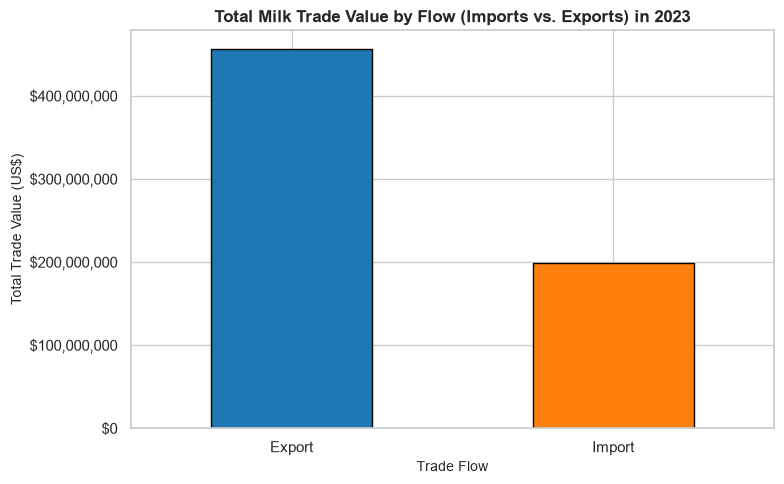

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))

# Aggregate trade values by flowCode (Imports vs Exports)
flow_totals = milk_df.groupby('flowCode')['trade_value'].sum()

# Create bar plot
ax = flow_totals.plot(kind='bar', color=['tab:blue', 'tab:orange'], edgecolor='black')

# Give the plot a title and labeled axes
plt.title("Total Milk Trade Value by Flow (Imports vs. Exports) in 2023", fontsize=12, fontweight='bold')
plt.xlabel("Trade Flow", fontsize=10)
plt.ylabel("Total Trade Value (US$)", fontsize=10)
plt.xticks(rotation=0)

# Format y-axis to be readable (in millions/billions)
ax.yaxis.set_major_formatter('${x:,.0f}')

plt.tight_layout()
plt.show()

This bar chart compares the total monetary value of UK milk and cream imports versus exports in 2023, highlighting a significant trade surplus driven by higher export volumes.

<!-- practice:start -->
---
## 🔁 SQL Practice

This week you split, applied and combined the UK milk-trade data with `groupby` and `pivot_table`, then plotted it. Now answer the same kind of questions **in SQL**, straight from the `week09` tables: `GROUP BY` is SQL's split-apply-combine.

**How it works**
1. Run the **practice setup** cell first (and again after restarting the kernel). It connects with your **read-only** account.
2. **SQL tasks:** write your query between the triple quotes and run the cell. `p.sql(...)` shows your result and
   says ✅ or ❌, and whether the **shape** (rows × columns) is right. Match the column order, sort order and rounding
   asked for (column *names* aren't checked).
3. Run `p.score()` at the end to see your practice score.

Refresh your memory with `Week-6 (Numpy & Pandas-1)/4-Intermediate SQL/Intermediate SQL.ipynb`.

In [20]:
# --- practice setup: run this cell first (don't edit it) ---
import sys, pathlib
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))
from db.practice import Practice, q

EXPECTED = {
 "s01": [
  [
   4,
   4
  ],
  "58c6ed3aa1049eff4acfe5edcb59b1d51d4a45f3579bb7c1db90ae2724f0e865"
 ],
 "s02": [
  [
   12,
   4
  ],
  "cf8e205c894ca889a22c89cfce94e601860d25931f62e999f4408800c74d8280"
 ],
 "s03": [
  [
   10,
   3
  ],
  "d6dcb9773bc969b74418a8b0a4bcc92581bf839100b25d7b16d2710934ca53d8"
 ],
 "s04": [
  [
   6,
   5
  ],
  "d940a4dfa48898fdeea545a6f4a693d039a8601cb0ad38d9f20bab0e641840d1"
 ],
 "s05": [
  [
   30,
   4
  ],
  "92f2c46acfb66aa693f51c79b678dbfed4d60714ebfb6c6a3a5d08e585879061"
 ]
}   # fingerprints only: the answers are not stored here
TITLES = {
 "s01": "Split-apply-combine: GROUP BY two columns",
 "s02": "A monthly imports vs exports table",
 "s03": "Subtotals with GROUPING SETS",
 "s04": "Top 3 partners per trade flow (window function)",
 "s05": "A tidy table for a stacked bar chart"
}
p = Practice(EXPECTED, TITLES)
print(f"Practice ready: {len(TITLES)} tasks. Connected as:", q("SELECT CURRENT_USER AS u").u[0])

Practice ready: 5 tasks. Connected as: intern_readonly


### SQL Task 1 · Split-apply-combine: GROUP BY two columns

Use the 2015 data, `week09.comtrade_milk_uk_jan_jul_15` (it covers January–May 2015). Group it by **trade flow** and
**milk type**, like the lesson's `milk.groupby([FLOW, COMMODITY])`. The milk type comes from the commodity code:
`'0401'` → `'unprocessed'`, `'0402'` → `'processed'`.

**Return:** `trade_flow`, `milk_type`, `partners` (how many **different** partner countries), `total_musd` (total
trade value in **millions** of US$, **rounded to 2 dp**). Sort by `trade_flow`, then `milk_type` (both A→Z).
⚠️ Remove the `Partner = 'World'` rows first: they are monthly totals, so keeping them counts everything twice.
💡 `CASE [Commodity Code] WHEN '0401' THEN ... END`, `COUNT(DISTINCT Partner)`, and `GROUP BY` the same `CASE`
expression.

In [21]:
SQL_01 = """
SELECT 
    "Trade Flow" AS trade_flow,
    CASE "Commodity Code"
        WHEN '0401' THEN 'unprocessed'
        WHEN '0402' THEN 'processed'
    END AS milk_type,
    COUNT(DISTINCT "Partner") AS partners,
    ROUND(SUM("Trade Value (US$)") / 1000000.0, 2) AS total_musd
FROM week09.comtrade_milk_uk_jan_jul_15
WHERE "Partner" <> 'World'
  AND "Commodity Code" IN ('0401', '0402')
GROUP BY "Trade Flow", 
         CASE "Commodity Code"
             WHEN '0401' THEN 'unprocessed'
             WHEN '0402' THEN 'processed'
         END
ORDER BY "Trade Flow" ASC, milk_type ASC;
"""

p.sql("s01", SQL_01)

KeyboardInterrupt: 

### SQL Task 2 · A monthly imports vs exports table

`week09.countrymilk` is the clean 2014 data: one row per month, flow, partner and commodity, with the
`'World'` rows already removed. Build the table that `pivot_table(index='Period', columns='Trade Flow', ...)` gives you,
but in SQL: **one row per month**, imports and exports side by side, plus the trade balance.

**Return:** `period` (e.g. `201401`), `imports_musd`, `exports_musd`, `balance_musd` (exports − imports), all in
**millions of US$, rounded to 2 dp**. Sort by `period`.
⚠️ Work out the balance from the **unrounded** sums and round only at the end (rounding first can be 0.01 off).
💡 Conditional aggregation: `SUM(CASE WHEN [Trade Flow] = 'Imports' THEN [Trade Value (US$)] ELSE 0 END)`. `PIVOT`
works too. Look at the result: is the balance positive in every month?

In [ ]:
SQL_02 = """
SELECT 
    "Period" AS period,
    ROUND(SUM(CASE WHEN "Trade Flow" = 'Imports' THEN "Trade Value (US$)" ELSE 0 END) / 1000000.0, 2) AS imports_musd,
    ROUND(SUM(CASE WHEN "Trade Flow" = 'Exports' THEN "Trade Value (US$)" ELSE 0 END) / 1000000.0, 2) AS exports_musd,
    ROUND((
        SUM(CASE WHEN "Trade Flow" = 'Exports' THEN "Trade Value (US$)" ELSE 0 END) - 
        SUM(CASE WHEN "Trade Flow" = 'Imports' THEN "Trade Value (US$)" ELSE 0 END)
    ) / 1000000.0, 2) AS balance_musd
FROM week09.countrymilk
GROUP BY "Period"
ORDER BY "Period" ASC;
"""

p.sql("s02", SQL_02)

,period,imports_musd,exports_musd,balance_musd
0,201401,52.37,87.14,34.76
1,201402,39.30,72.49,33.19
2,201403,44.32,86.78,42.46
3,201404,44.21,95.20,50.99
4,201405,48.08,96.20,48.13
5,201406,45.10,99.32,54.21
6,201407,44.80,72.88,28.08
7,201408,40.29,61.74,21.44
8,201409,56.70,60.60,3.90
9,201410,56.37,57.00,0.64


✅ s02: correct!


,period,imports_musd,exports_musd,balance_musd
0,201401,52.37,87.14,34.76
1,201402,39.30,72.49,33.19
2,201403,44.32,86.78,42.46
3,201404,44.21,95.20,50.99
4,201405,48.08,96.20,48.13
5,201406,45.10,99.32,54.21
6,201407,44.80,72.88,28.08
7,201408,40.29,61.74,21.44
8,201409,56.70,60.60,3.90
9,201410,56.37,57.00,0.64


### SQL Task 3 · Subtotals with GROUPING SETS

A manager wants a **quarterly report for 2014** (`week09.countrymilk`) with a **year subtotal** under each trade
flow, in one query.

**Return:** `trade_flow`, `quarter` (`'Q1'` … `'Q4'`, or `'Year'` on the subtotal row), `total_musd` (millions of
US$, **rounded to 2 dp**). That is 10 rows: for each flow, Q1–Q4 and then its `'Year'` row. Sort by `trade_flow`
(A→Z), then the quarters in order, with the `'Year'` row last.
💡 Quarter from `Period`: `(Period % 100 + 2) / 3` gives 1–4 (integer division). Then
`GROUP BY GROUPING SETS ((flow, quarter), (flow))`, and `GROUPING(quarter) = 1` tells you a row is a subtotal.
⚠️ Don't add a grand total over both flows: adding imports to exports is not a meaningful number.

In [ ]:
SQL_03 = """
WITH base AS (
    SELECT 
        "Trade Flow" AS trade_flow,
        (("Period" % 100 + 2) / 3) AS q_num,
        "Trade Value (US$)"
    FROM week09.countrymilk
)
SELECT 
    trade_flow,
    CASE 
        WHEN GROUPING(q_num) = 1 THEN 'Year'
        ELSE 'Q' || q_num
    END AS quarter,
    ROUND(SUM("Trade Value (US$)") / 1000000.0, 2) AS total_musd
FROM base
GROUP BY GROUPING SETS (
    (trade_flow, q_num),
    (trade_flow)
)
ORDER BY 
    trade_flow ASC,
    GROUPING(q_num) ASC,
    q_num ASC;
"""

p.sql("s03", SQL_03)

,trade_flow,quarter,total_musd
0,Exports,Q1,246.41
1,Exports,Q2,290.71
2,Exports,Q3,195.22
3,Exports,Q4,166.31
4,Exports,Year,898.65
5,Imports,Q1,135.99
6,Imports,Q2,137.39
7,Imports,Q3,141.79
8,Imports,Q4,148.71
9,Imports,Year,563.88


✅ s03: correct!


,trade_flow,quarter,total_musd
0,Exports,Q1,246.41
1,Exports,Q2,290.71
2,Exports,Q3,195.22
3,Exports,Q4,166.31
4,Exports,Year,898.65
5,Imports,Q1,135.99
6,Imports,Q2,137.39
7,Imports,Q3,141.79
8,Imports,Q4,148.71
9,Imports,Year,563.88


### SQL Task 4 · Top 3 partners per trade flow (window function)

Project 4 asks: *which are the main trading partners?* Answer it for **both flows at once** using 2014
(`week09.countrymilk`): the **top 3 partners by total trade value in each trade flow**, and each partner's share of
that flow's total.

**Return:** `trade_flow`, `rank` (1–3), `partner`, `total_musd` (millions of US$, **rounded to 2 dp**), `share_pct`
(the partner's % of **its flow's** total over all partners, **rounded to 1 dp**). Sort by `trade_flow`, then `rank`.
💡 First total per (flow, partner) in a CTE. Then `ROW_NUMBER() OVER (PARTITION BY flow ORDER BY total DESC,
partner)` and `SUM(total) OVER (PARTITION BY flow)` for the share. Filter `rank <= 3` in the outer query (you can't
filter on a window function in the same `WHERE`).

In [ ]:
SQL_04 = """
WITH partner_totals AS (
    SELECT 
        "Trade Flow" AS trade_flow,
        "Partner" AS partner,
        SUM("Trade Value (US$)") AS total_val
    FROM week09.countrymilk
    GROUP BY "Trade Flow", "Partner"
),
ranked AS (
    SELECT 
        trade_flow,
        partner,
        total_val,
        CAST(ROW_NUMBER() OVER (PARTITION BY trade_flow ORDER BY total_val DESC, partner ASC) AS INTEGER) AS rank,
        SUM(total_val) OVER (PARTITION BY trade_flow) AS flow_total
    FROM partner_totals
)
SELECT 
    trade_flow,
    rank,
    partner,
    ROUND(CAST(total_val AS NUMERIC) / 1000000.0, 2) AS total_musd,
    ROUND(CAST(total_val AS NUMERIC) * 100.0 / CAST(flow_total AS NUMERIC), 1) AS share_pct
FROM ranked
WHERE rank <= 3
ORDER BY trade_flow ASC, rank ASC;
"""

p.sql("s04", SQL_04)

,trade_flow,rank,partner,total_musd,share_pct
0,Exports,1,Ireland,421.23,46.9
1,Exports,2,Algeria,93.75,10.4
2,Exports,3,Netherlands,68.65,7.6
3,Imports,1,Ireland,174.32,30.9
4,Imports,2,France,105.01,18.6
5,Imports,3,Germany,76.61,13.6


✅ s04: correct!


,trade_flow,rank,partner,total_musd,share_pct
0,Exports,1,Ireland,421.23,46.9
1,Exports,2,Algeria,93.75,10.4
2,Exports,3,Netherlands,68.65,7.6
3,Imports,1,Ireland,174.32,30.9
4,Imports,2,France,105.01,18.6
5,Imports,3,Germany,76.61,13.6


### SQL Task 5 · A tidy table for a stacked bar chart

For **Part B** you want a stacked bar chart of the UK's **2015 exports** (`week09.comtrade_milk_uk_jan_jul_15`):
one bar per month, split into the **5 biggest export partners** plus one `'Other'` slice for everyone else. Seaborn
likes **tidy (long)** data: one row per month and partner group. Build that table in SQL.

The "top 5" are the 5 partners with the largest **total** exports over all five months (ties: partner A→Z). Every
other partner becomes `'Other'`.

**Return:** `period`, `partner_group`, `exports_musd` (millions of US$, **rounded to 2 dp**), `share_pct` (the group's
% of **that month's** exports, **rounded to 1 dp**). 30 rows. Sort by `period`, then `partner_group` A→Z but with
`'Other'` last in each month.
⚠️ Exports only, and no `'World'` rows.
💡 CTE 1: the export rows. CTE 2: `SELECT TOP 5 Partner ... GROUP BY Partner ORDER BY SUM(...) DESC, Partner`.
`LEFT JOIN` the rows to the top 5 and use `CASE` to label the rest `'Other'`. For the share:
`SUM(SUM(v)) OVER (PARTITION BY period)` (a window over a grouped result).

In [ ]:
import base64
s1 = "CldJVEggZSBBUyAoCiAgICBTRUxFQ1QgIlBlcmlvZCIgQVMgcCwgIlBhcnRuZXIiIEFTIHIsICJUcmFkZSBWYWx1ZSAoVVMkKSIgQVMgdiAKICAgIEZST00gd2VlazA5LmNvbXRyYWRlX21pbktfdWtfamFuX2p1bF8xNSAKICAgIFdIRVJFICJUcmFkZSBGbG93IiA9ICdFeHBvcnRzJyBBTkQgIlBhcnRuZXIiICE9ICdXb3JsZCcKKSwKdCBBUyAoCiAgICBTRUxFQ1QgciAKICAgIEZST00gZSAKICAgIEdST1VQIEJZIHIgCiAgICBPUkRFUiBCWSBTVU0odikgREVTQyAKICAgIExJTUlUIDUKKSwKZyBBUyAoCiAgICBTRUxFQ1QgCiAg"

### Practice score
Run this when you're done.

In [ ]:
p.score()

Task Type                                           Topic Result
 s01  SQL       Split-apply-combine: GROUP BY two columns      ✅
 s02  SQL              A monthly imports vs exports table      ✅
 s03  SQL                    Subtotals with GROUPING SETS      ✅
 s04  SQL Top 3 partners per trade flow (window function)      ✅
 s05  SQL            A tidy table for a stacked bar chart      ❌
SQL score: 4 / 5


,Task,Type,Topic,Result
0,s01,SQL,Split-apply-combine: GROUP BY two columns,✅
1,s02,SQL,A monthly imports vs exports table,✅
2,s03,SQL,Subtotals with GROUPING SETS,✅
3,s04,SQL,Top 3 partners per trade flow (window function),✅
4,s05,SQL,A tidy table for a stacked bar chart,❌


<!-- practice:end -->

---
## 📰 Article Link

Write a **detailed article** about this week's work. It should cover:

- **What you learnt:** the key concepts, tools and techniques from this week.
- **What you solved:** the tasks and projects you worked on, and how you approached them.
- **Challenges you faced:** what was hard, confusing or didn't work at first.
- **How you overcame them:** what you tried, what finally worked, and what you'd do differently.
- **Anything else you want to share:** insights, results, visuals, or advice for others learning this.

Publish it, then paste the article's **URL** in the empty cell below (double-click the cell to edit it).